# Stadler et al. (2022): sorption-enhanced water-gas shift on K-HDMO

Validation of RUPTURA against *Dynamic simulation of a compact sorption-enhanced
water-gas shift reactor*, T. J. Stadler, L. J. Bender, P. Pfeifer, Front. Chem.
Eng. **4** (2022) 1000064,
[doi:10.3389/fceng.2022.1000064](https://doi.org/10.3389/fceng.2022.1000064)
(`fceng-04-1000064.pdf`).

**Reference data.** Figures 4-8 of the article are vector graphics, so
`digitize_reference.py` reads every marker and curve straight from the PDF paths
into `reference_digitized/` (SI units).  The calibration is exact: the digitised
Freundlich fit of Figure 5 matches Table 3 to 0.02 %, and the digitised
equilibrium lines of Figure 4 match Moe's $K_{\mathrm{eq}}$ (Eq. 5) to four decimal places.

**Simulations.** `generate.py` writes every case and `run.py` runs them (eight
workers).  Conversions are in `conversions.md`.

| figure | content | RUPTURA case |
| --- | --- | --- |
| 4 | steady-state WGS conversion, 225-275 $^\circ$C | `figure4_wgs_conversion/` (51 runs), `figure4_grid_study_548K_SG4p5/` |
| 5 | CO$_2$ isotherm, 523 K | `figure5_isotherm_CO2_523K` |
| 6, 8A | sorbent-only cycles | `figure6_8a_sorbent_only_cycles_8bar-1bar_523K` (5 cycles) |
| 7, 8B | SE-WGS cycles | `figure7_8b_sewgs_cycles_8bar-1bar_523K` (5 cycles, catalyst in the first quarter) |

**Model set-up** (Table 3 and Section 2 of the paper unless noted):

| quantity | value |
| --- | --- |
| isotherm | Freundlich, $k_{\mathrm{Fr}}$ = 0.177 mmol g$^{-1}$ bar$^{-1/n}$, $1/n_{\mathrm{Fr}}$ = 0.220 |
| sorption kinetics | $k_{\mathrm{ads}}$ = 0.1125 s$^{-1}$; desorption $k^1_{\mathrm{des}}\exp[\beta_{\mathrm{des}}(q/q_{\max})/RT]$, $k^1_{\mathrm{des}}$ = 5.38$\times$10$^{-4}$ s$^{-1}$, $\beta_{\mathrm{des}}$ = 74 kJ mol$^{-1}$, $q_{\max} = q^*$(20 bar) |
| WGS | Eq. 4 with $k_\infty$ = 2.01$\times$10$^5$ mol bar$^{-2}$ g$^{-1}$ h$^{-1}$, $E_a$ = 51.845 kJ mol$^{-1}$, Moe's $K_{\mathrm{eq}}$; catalyst-weighted reaction on the bulk gas |
| bed | two slits, 2 mm $\times$ 50 mm $\times$ 100 mm; $\varepsilon_b$ = 0.4; $r_p$ = 100 µm; 9.70 g sorbent (sorbent only), 9.35 g sorbent with 0.51 g catalyst in the first quarter (SE-WGS) |
| adsorption step | 15 min, 8 bar, 523.15 K, 2000 mL min$^{-1}$ (STP) |
| regeneration step | 40 min, 1 bar, H$_2$O/N$_2$ = 0.4/0.6, 1000 mL min$^{-1}$ (STP) |
| axial dispersion | $D_{\mathrm{ax}} = D_{\mathrm{mix}}\sqrt{\varepsilon_b} + u r_p$ (Eq. 12), Fuller $D_{\mathrm{mix}}$ in N$_2$ |

The breakthrough flow rates are not in the 2022 paper; they are taken from Table 2
of Stadler et al., Energies 14 (2021) 355, which uses the same protocol.

**Extra-column mixing.** The measured outlet curves are broadened by back-mixing in
the tubing between the reactor and the analyser; the reactor itself holds the gas
for only about 1 s.  CO does not adsorb, so in the sorbent-only runs its measured
curve is the step response of everything downstream of the feed.  The simulated bed
outlet is passed through that measured response (a convolution with the measured CO
of the same cycle), which needs no fitted residence-time model.  In the SE-WGS runs
CO reacts, so the measured CO of Figure 8A (same set-up and flow) serves as the
response.

In [1]:
import json
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
# The panels go into the paper; they are printed at 0.49 of the A4 text width (3.07 in), i.e. at 38% of their
# 8 in width, so the 21-23 pt fonts print at about 8 pt.
FIGURES = ROOT.parents[2] / "ruptura-2.0-paper" / "figures" / "stadler"
FIGURES.mkdir(parents=True, exist_ok=True)
REFERENCE = ROOT / "reference_digitized"

plt.style.use("default")
plt.rcParams.update({
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 23,
    "xtick.labelsize": 21,
    "ytick.labelsize": 21,
    "axes.labelsize": 23,
    "legend.fontsize": 21,
    "legend.title_fontsize": 21,
    "axes.titlesize": 25,
    "figure.titlesize": 25,
    "lines.linewidth": 3.0,
    "lines.markersize": 11,
    "lines.markeredgewidth": 1.8,
    "axes.linewidth": 1.5,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "legend.handlelength": 1.6,
    "legend.labelspacing": 0.3,
    "legend.borderaxespad": 0.3,
    "legend.columnspacing": 1.0,
    "axes.grid": False,
    "axes.labelpad": 6.0,
    "pdf.fonttype": 42,
})

R = 8.31446261815324
ISOTHERM_CASE = "figure5_isotherm_CO2_523K"
CONVERSION_CASES = ROOT / "figure4_wgs_conversion"
GRID_STUDY_CASES = ROOT / "figure4_grid_study_548K_SG4p5"
SORBENT_ONLY_CASE = "figure6_8a_sorbent_only_cycles_8bar-1bar_523K"
SEWGS_CASE = "figure7_8b_sewgs_cycles_8bar-1bar_523K"
ADSORPTION_TIME = 900.0     # s
CYCLE_PERIOD = 3300.0       # s, 15 min adsorption + 40 min regeneration
NUMBER_OF_CYCLES = 5

In [2]:
# ---------------------------------------------------------------- data readers
def read_reference(name):
    '''One digitised series from reference_digitized/: first and second column.'''
    data = np.loadtxt(REFERENCE / f"{name}.csv", delimiter=",", skiprows=1, ndmin=2)
    return data[:, 0], data[:, 1]


@lru_cache(maxsize=None)
def load_component(case, index, name):
    '''Full component output of one case (cached: the cycle files are large).'''
    return np.loadtxt(ROOT / case / f"component_{index}_{name}.data", comments="#")


def read_outlet(case, index, name):
    '''Outlet time in s and wet outlet mole fraction of one component.'''
    data = load_component(case, index, name)
    position = data[:, 2]
    outlet = position > position.max() - 1.0e-9
    time_s = data[outlet, 1] * 60.0
    order = np.argsort(time_s)
    return time_s[order], np.clip(data[outlet, 5][order], 0.0, None)


def dry_outlet(case):
    '''Time and dry outlet fractions of CO and CO2 (components 1, 2; H2O is component 4).'''
    time_s, carbon_monoxide = read_outlet(case, 1, "CO")
    _, carbon_dioxide = read_outlet(case, 2, "CO2")
    _, water = read_outlet(case, 4, "H2O")
    return time_s, carbon_monoxide / (1.0 - water), carbon_dioxide / (1.0 - water)


def crossing(time_s, fraction, level):
    '''Time at which a monotonised curve first reaches `level`.'''
    rising = np.maximum.accumulate(fraction)
    if rising[-1] < level:
        return np.nan
    return float(np.interp(level, rising, time_s))


def half_times(co_time, co, co2_time, co2):
    '''Half-height times of the normalised CO and CO2 curves.'''
    return crossing(co_time, co / co[-1], 0.5), crossing(co2_time, co2 / co2[-1], 0.5)


def through_tracer_response(time_s, fraction, tracer_time, tracer_fraction, bed_delay):
    '''Pass a simulated bed-outlet curve through the measured extra-column response.

    The measured CO curve, normalised by its final value, is the step response F(s)
    of reactor, tubing and analyser.  The reactor's own gas residence time is already
    in the simulated curve, so F is shifted back by `bed_delay`, the simulated CO
    half-time at the bed outlet.  y_measured(t) = sum_j y_bed(t - s_j) dF(s_j).
    '''
    lag = np.arange(0.0, tracer_time.max(), 0.25)
    response = np.interp(lag + bed_delay, tracer_time, tracer_fraction / tracer_fraction[-1])
    response = np.maximum.accumulate(np.clip(response, 0.0, 1.0))
    weights = np.diff(response, prepend=0.0)
    return np.array([np.sum(np.interp(t - lag, time_s, fraction, left=0.0) * weights)
                     for t in time_s])


def adsorption_step(case, cycle, tracer=None):
    '''Dry outlet CO and CO2 of one adsorption step, time from the start of the step.

    With a measured tracer (time, fraction) the bed outlet is passed through it; the
    response applies to the dry fractions, as the tracer is itself a dry signal.
    '''
    time_s, carbon_monoxide, carbon_dioxide = dry_outlet(case)
    start = (cycle - 1) * CYCLE_PERIOD
    step = (time_s >= start) & (time_s < start + ADSORPTION_TIME)
    time_s, carbon_monoxide, carbon_dioxide = time_s[step] - start, carbon_monoxide[step], carbon_dioxide[step]
    if tracer is not None:
        bed_delay = crossing(time_s, carbon_monoxide / carbon_monoxide[-1], 0.5)
        carbon_monoxide, carbon_dioxide = (through_tracer_response(time_s, y, *tracer, bed_delay)
                                           for y in (carbon_monoxide, carbon_dioxide))
    return time_s, carbon_monoxide, carbon_dioxide


def bed_average_loading(case):
    '''Time in s and the axial mean CO2 loading (physisorbed + chemisorbed) in mol/kg.'''
    data = load_component(case, 2, "CO2")
    time_s = data[:, 1] * 60.0
    loading = data[:, 6] + data[:, 8]
    times, starts = np.unique(time_s, return_index=True)
    average = np.empty_like(times)
    for index, start in enumerate(starts):
        stop = starts[index + 1] if index + 1 < starts.size else data.shape[0]
        order = np.argsort(data[start:stop, 2])
        z = data[start:stop, 2][order]
        average[index] = np.trapezoid(loading[start:stop][order], z) / (z[-1] - z[0])
    return times, average


def steady_conversion(directory):
    '''CO conversion at the outlet at the last output time; total flow is constant (WGS is equimolar).'''
    data = np.loadtxt(directory / "component_1_CO.data", comments="#")
    position = data[:, 2]
    outlet = position > position.max() - 1.0e-9
    last = np.argmax(data[outlet, 1])
    feed = data[0, 5]
    return 1.0 - data[outlet, 5][last] / feed


def plug_flow_conversion(temperature, steam_to_gas, flow_stp=2000.0, catalyst_mass=0.5e-3,
                         carbon_monoxide=0.10, pressure_bar=8.0, steps=4000):
    '''Ideal plug-flow WGS conversion, Eq. 4 integrated over the catalyst mass (RK4).'''
    molar_flow = 101325.0 * flow_stp * 1.0e-6 / 60.0 / (R * 273.15)
    k = 2.01e5 * np.exp(-51845.0 / (R * temperature)) * 1.0e3 / 3600.0
    equilibrium = np.exp(4577.8 / temperature - 4.33)
    rate = lambda x: (k * pressure_bar ** 2 * carbon_monoxide ** 2
                      * ((1.0 - x) * (steam_to_gas - x) - x * x / equilibrium) / (molar_flow * carbon_monoxide))
    conversion, dw = 0.0, catalyst_mass / steps
    for _ in range(steps):
        k1 = rate(conversion)
        k2 = rate(conversion + 0.5 * dw * k1)
        k3 = rate(conversion + 0.5 * dw * k2)
        k4 = rate(conversion + dw * k3)
        conversion += dw * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0
    return conversion


def marker_stride(count, maximum=20):
    '''Stride that keeps at most `maximum` markers on a digitised trace.'''
    return max(1, int(np.ceil(count / maximum)))


def plot_reference(axis, x, y, colour, marker, **kwargs):
    '''Digitised paper data: dashed line, open markers, at most 20 of them.'''
    return axis.plot(x, y, linestyle="--", linewidth=2.2, color=colour,
                     marker=marker, markevery=marker_stride(len(x)),
                     markerfacecolor="none", markeredgecolor=colour, **kwargs)[0]

## Figure 5 - CO$_2$ isotherm on K-HDMO at 523 K

The pure-CO$_2$ Freundlich isotherm of Table 3 evaluated by RUPTURA's
`MixturePrediction`, against the measured isotherm and the authors' fit.

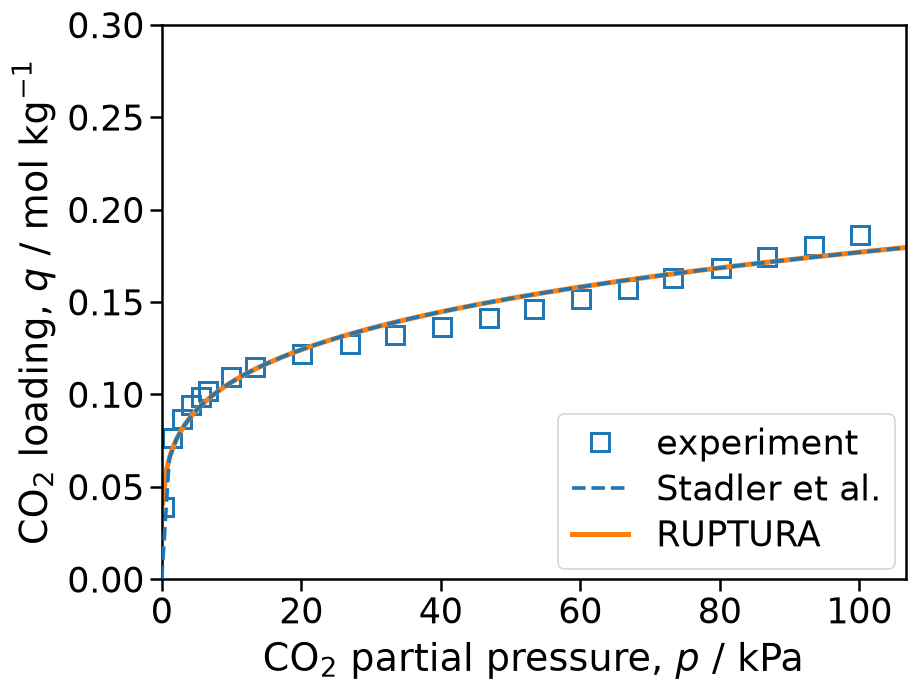

RUPTURA against Table 3: max relative deviation 4.8e-14


In [3]:
pressure, loading = read_reference("figure5_experiment")
fit_pressure, fit_loading = read_reference("figure5_freundlich_fit")
data = np.loadtxt(ROOT / ISOTHERM_CASE / "component_0_CO2.data", comments="#")

fig, ax = plt.subplots()
ax.plot(pressure / 1.0e3, loading, linestyle="none", marker="s", markerfacecolor="none",
        markeredgecolor="C0", label="experiment")
ax.plot(fit_pressure / 1.0e3, fit_loading, linestyle="--", linewidth=2.2, color="C0", zorder=3,
        label="Stadler et al.")
ax.plot(data[:, 0] / 1.0e3, data[:, 1], color="C1", label="RUPTURA")
ax.set(xlim=(0.0, 800.0 * 133.322387415 / 1.0e3), ylim=(0.0, 0.3),
       xlabel=r"CO$_2$ partial pressure, $p$ / kPa",
       ylabel=r"CO$_2$ loading, $q$ / mol kg$^{-1}$")
ax.legend(loc="lower right")
fig.savefig(FIGURES / "figure_5.pdf", bbox_inches="tight")
plt.show()

model = 0.177 * (data[:, 0] / 1.0e5) ** 0.220
print(f"RUPTURA against Table 3: max relative deviation {np.max(np.abs(data[:, 1] / model - 1.0)):.1e}")

## Figure 4 - steady-state CO conversion

0.50 g of catalyst in the first quarter of the slits (25 mm), 8 bar, 2000 mL min$^{-1}$,
10 % CO and $S/G = \dot n_{\mathrm{H_2O}}/\dot n_{\mathrm{CO}}$.  RUPTURA simulates the catalyst
section only (the inert SiC downstream does not change the steady state) with the WGS
as a catalyst-weighted reaction on the bulk gas, on 400 cells, until the outlet is
steady.  Dotted lines: equilibrium conversion from Moe's $K_{\mathrm{eq}}$ (Eq. 5).

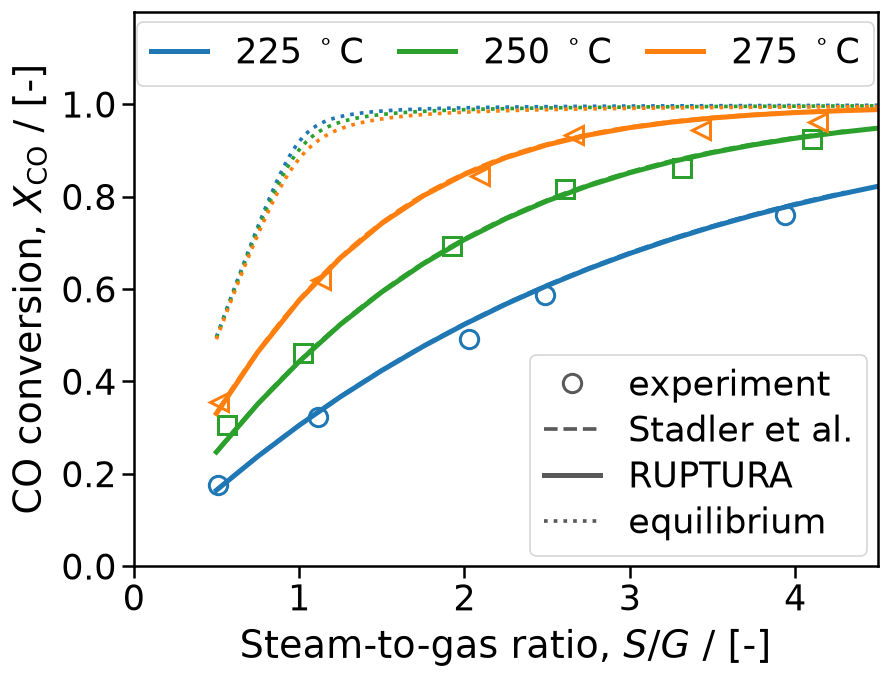

RUPTURA minus plug-flow conversion over all 51 runs: -0.0019 to -0.0003


In [4]:
fig, ax = plt.subplots()
for colour, marker, celsius in (("C0", "o", 225), ("C2", "s", 250), ("C1", "<", 275)):
    kelvin = round(celsius + 273.15)
    steam_to_gas, conversion = read_reference(f"figure4_experiment_{kelvin}K")
    ax.plot(steam_to_gas, conversion, linestyle="none", marker=marker, markerfacecolor="none",
            markeredgecolor=colour)
    model_ratio, model_conversion = read_reference(f"figure4_model_{kelvin}K")
    ax.plot(model_ratio, model_conversion, color=colour, linestyle="--", linewidth=2.2)

    runs = sorted(CONVERSION_CASES.glob(f"{kelvin}K_SG*"),
                  key=lambda path: float(path.name.split("SG")[1].replace("p", ".")))
    ratios = [float(path.name.split("SG")[1].replace("p", ".")) for path in runs]
    ax.plot(ratios, [steady_conversion(path) for path in runs], color=colour, label=rf"{celsius} $^\circ$C")

    # Equilibrium of CO + H2O = CO2 + H2: X^2 = K (1 - X)(S/G - X).
    ratio = np.linspace(0.5, 4.5, 200)
    equilibrium = np.exp(4577.8 / (celsius + 273.15) - 4.33)
    a, b, c = 1.0 - equilibrium, equilibrium * (1.0 + ratio), -equilibrium * ratio
    ax.plot(ratio, (-b + np.sqrt(b * b - 4.0 * a * c)) / (2.0 * a), color=colour, linestyle=":",
            linewidth=2.2)

temperatures = ax.legend(loc="upper center", ncol=3)
ax.add_artist(temperatures)
styles = [plt.Line2D([], [], color="0.35", linestyle="none", marker="o", markerfacecolor="none"),
          plt.Line2D([], [], color="0.35", linestyle="--", linewidth=2.2),
          plt.Line2D([], [], color="0.35"),
          plt.Line2D([], [], color="0.35", linestyle=":", linewidth=2.2)]
ax.legend(styles, ["experiment", "Stadler et al.", "RUPTURA", "equilibrium"], loc="lower right")
ax.set(xlim=(0.0, 4.5), ylim=(0.0, 1.2), yticks=np.arange(0.0, 1.01, 0.2),
       xlabel=r"Steam-to-gas ratio, $S/G$ / [-]", ylabel=r"CO conversion, $X_{\mathrm{CO}}$ / [-]")
fig.savefig(FIGURES / "figure_4.pdf", bbox_inches="tight")
plt.show()

deviation = []
for path in CONVERSION_CASES.iterdir():
    kelvin = float(path.name.split("K_")[0])
    ratio = float(path.name.split("SG")[1].replace("p", "."))
    deviation.append(steady_conversion(path) - plug_flow_conversion(kelvin + 0.15, ratio))
print(f"RUPTURA minus plug-flow conversion over all {len(deviation)} runs: "
      f"{min(deviation):+.4f} to {max(deviation):+.4f}")

## Numerical dispersion: grid study

The bulk balance discretises convection with a first-order upwind difference, which
adds a numerical dispersion $v\,\Delta z/2$.  With the physical dispersion switched off,
the fastest Figure 4 case (275 $^\circ$C, $S/G$ = 4.5) converges to the ideal plug-flow
conversion as the grid is refined; the error halves with every doubling of the
number of cells.

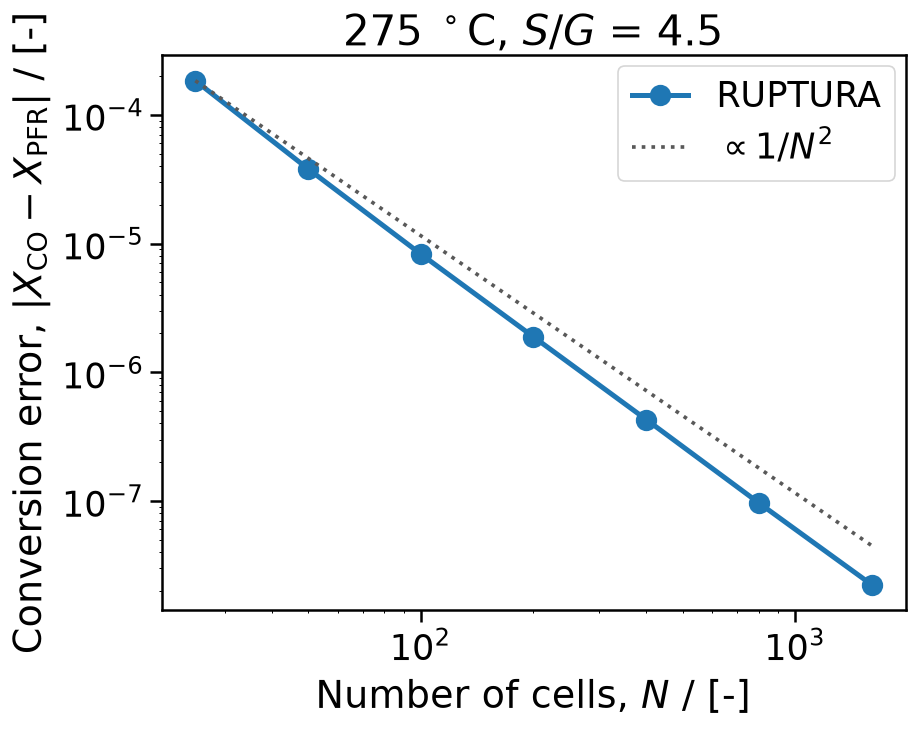

 cells  |X - X_PFR|
    25 1.842421e-04
    50 3.807895e-05
   100 8.292489e-06
   200 1.883010e-06
   400 4.290980e-07
   800 9.638060e-08
  1600 2.235221e-08


In [5]:
cells, errors = [], []
for path in sorted(GRID_STUDY_CASES.iterdir(), key=lambda path: int(path.name[1:])):
    cells.append(int(path.name[1:]))
    errors.append(abs(steady_conversion(path) - plug_flow_conversion(548.15, 4.5)))
cells, errors = np.array(cells), np.array(errors)

fig, ax = plt.subplots()
ax.plot(cells, errors, color="C0", marker="o", label="RUPTURA")
ax.plot(cells, errors[0] * (cells[0] / cells) ** 2, color="0.35", linestyle=":", linewidth=2.2,
        label=r"$\propto 1/N^2$")
ax.set(xscale="log", yscale="log",
       xlabel=r"Number of cells, $N$ / [-]",
       ylabel=r"Conversion error, $|X_{\mathrm{CO}} - X_{\mathrm{PFR}}|$ / [-]",
       title=r"275 $^\circ$C, $S/G$ = 4.5")
ax.legend(loc="upper right")
fig.savefig(FIGURES / "figure_4_grid_study.pdf", bbox_inches="tight")
plt.show()

print(pd.DataFrame({"cells": cells, "|X - X_PFR|": errors}).to_string(index=False))

## Figure 6 - sorbent-only cycles 1-5

CO$_2$ at the analyser for the five measured cycles (dashed, open markers) and the five
simulated cycles (solid), each passed through the measured CO of its own cycle.  The
simulation starts from a clean bed and repeats 15 min adsorption at 8 bar and 40 min
regeneration at 1 bar.

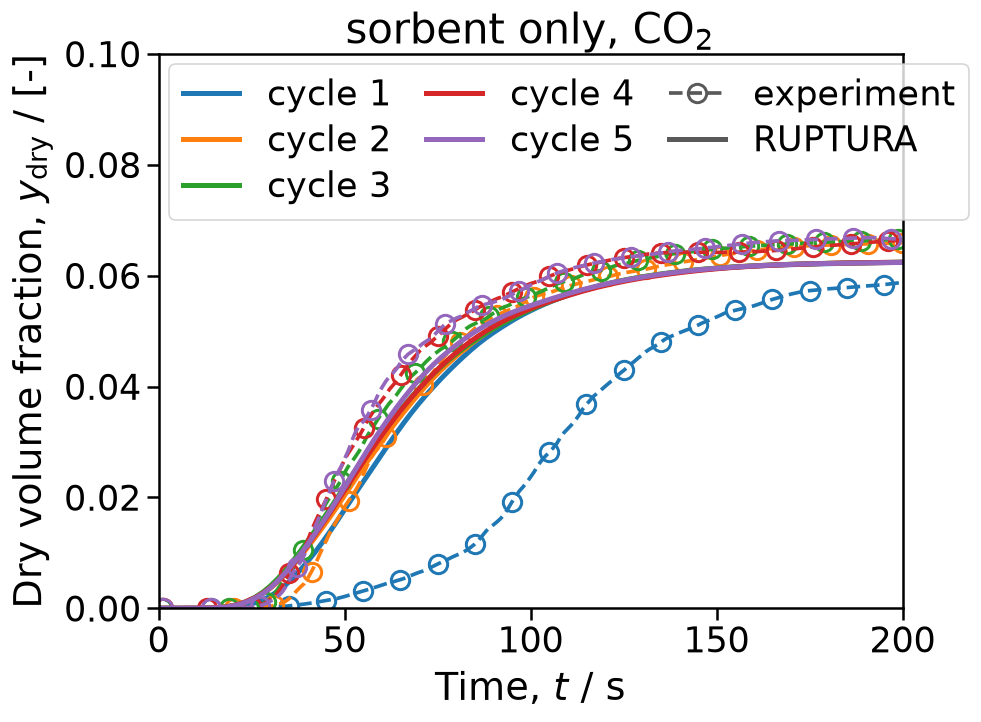

In [6]:
fig, ax = plt.subplots()
for cycle in range(1, NUMBER_OF_CYCLES + 1):
    colour = f"C{cycle - 1}"
    tracer = read_reference(f"figure6_cycle{cycle}_CO")
    measured_time, measured = read_reference(f"figure6_cycle{cycle}_CO2")
    plot_reference(ax, measured_time, measured, colour, "o")
    time_s, _, carbon_dioxide = adsorption_step(SORBENT_ONLY_CASE, cycle, tracer)
    ax.plot(time_s, carbon_dioxide, color=colour, label=f"cycle {cycle}")

ax.plot([], [], color="0.35", linestyle="--", linewidth=2.2, marker="o", markerfacecolor="none",
        label="experiment")
ax.plot([], [], color="0.35", label="RUPTURA")
ax.set(xlim=(0.0, 200.0), ylim=(0.0, 0.1), title="sorbent only, CO$_2$",
       xlabel=r"Time, $t$ / s", ylabel=r"Dry volume fraction, $y_{\mathrm{dry}}$ / [-]")
ax.legend(loc="upper left", ncol=3)
fig.savefig(FIGURES / "figure_6.pdf", bbox_inches="tight")
plt.show()

## Figure 8A - third sorbent-only cycle

Measured (open markers), the authors' model (dotted) and RUPTURA (solid), both
models in their third cycle; RUPTURA is passed through the measured CO of this cycle.

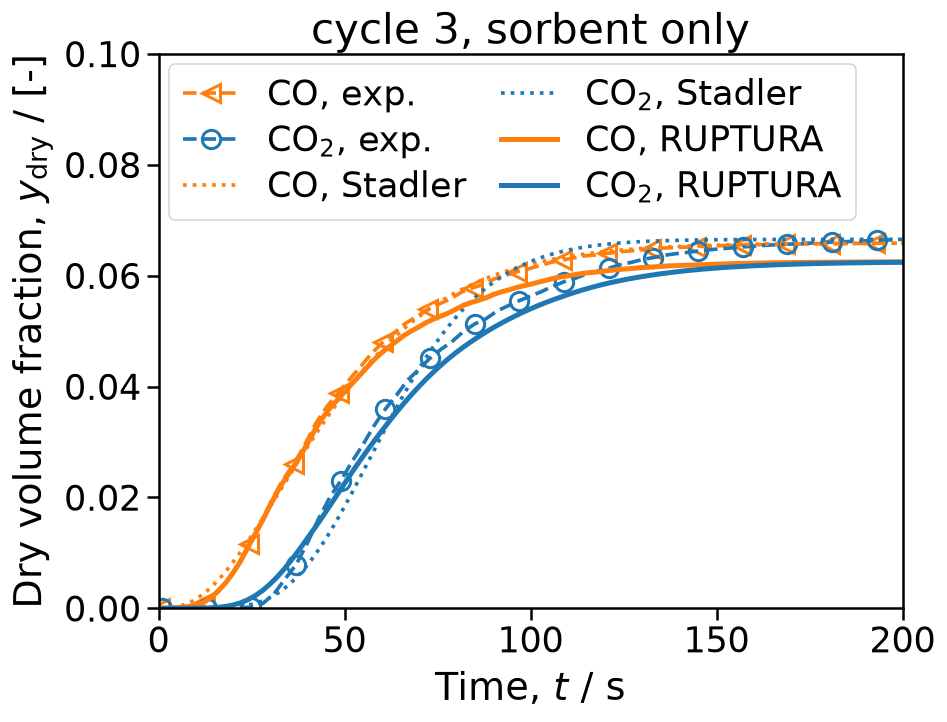

In [7]:
co_time, co_fraction = read_reference("figure8a_experiment_CO")
co2_time, co2_fraction = read_reference("figure8a_experiment_CO2")
model_co_time, model_co = read_reference("figure8a_simulation_CO")
model_co2_time, model_co2 = read_reference("figure8a_simulation_CO2")
time_s, co_simulated, co2_simulated = adsorption_step(SORBENT_ONLY_CASE, 3, (co_time, co_fraction))

fig, ax = plt.subplots()
plot_reference(ax, co_time, co_fraction, "C1", "<", label="CO, exp.")
plot_reference(ax, co2_time, co2_fraction, "C0", "o", label=r"CO$_2$, exp.")
ax.plot(model_co_time, model_co, color="C1", linestyle=":", linewidth=2.2, label="CO, Stadler")
ax.plot(model_co2_time, model_co2, color="C0", linestyle=":", linewidth=2.2, label=r"CO$_2$, Stadler")
ax.plot(time_s, co_simulated, color="C1", label="CO, RUPTURA")
ax.plot(time_s, co2_simulated, color="C0", label=r"CO$_2$, RUPTURA")
ax.set(xlim=(0.0, 200.0), ylim=(0.0, 0.1), title="cycle 3, sorbent only",
       xlabel=r"Time, $t$ / s", ylabel=r"Dry volume fraction, $y_{\mathrm{dry}}$ / [-]")
ax.legend(loc="upper left", ncol=2)
fig.savefig(FIGURES / "figure_8a.pdf", bbox_inches="tight")
plt.show()

## Figure 7 - SE-WGS cycles

Catalyst and sorbent in the first quarter, sorbent downstream; feed CO/H$_2$O/N$_2$ =
0.05/0.2/0.75.  CO reacts here, so the measured CO of Figure 8A (same set-up and flow)
is used as the extra-column response.  Measured cycles 1, 3 and 63 against simulated
cycles 1, 3 and 5 (the simulation is periodic from cycle 2 on).

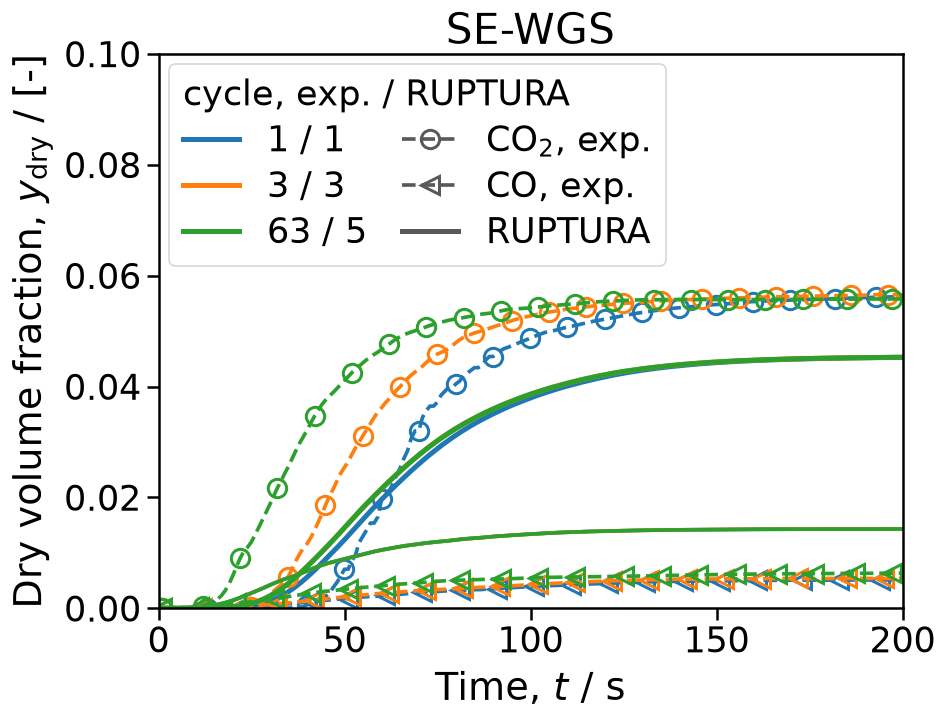

In [8]:
tracer = read_reference("figure8a_experiment_CO")
fig, ax = plt.subplots()
for colour, measured_cycle, simulated_cycle in (("C0", 1, 1), ("C1", 3, 3), ("C2", 63, 5)):
    measured_time, measured = read_reference(f"figure7_cycle{measured_cycle}_CO2")
    plot_reference(ax, measured_time, measured, colour, "o")
    measured_time, measured = read_reference(f"figure7_cycle{measured_cycle}_CO")
    plot_reference(ax, measured_time, measured, colour, "<")
    time_s, carbon_monoxide, carbon_dioxide = adsorption_step(SEWGS_CASE, simulated_cycle, tracer)
    ax.plot(time_s, carbon_dioxide, color=colour, label=f"{measured_cycle} / {simulated_cycle}")
    ax.plot(time_s, carbon_monoxide, color=colour, linewidth=2.2)

ax.plot([], [], color="0.35", linestyle="--", linewidth=2.2, marker="o", markerfacecolor="none",
        label=r"CO$_2$, exp.")
ax.plot([], [], color="0.35", linestyle="--", linewidth=2.2, marker="<", markerfacecolor="none",
        label="CO, exp.")
ax.plot([], [], color="0.35", label="RUPTURA")
ax.set(xlim=(0.0, 200.0), ylim=(0.0, 0.1), title="SE-WGS",
       xlabel=r"Time, $t$ / s", ylabel=r"Dry volume fraction, $y_{\mathrm{dry}}$ / [-]")
ax.legend(loc="upper left", ncol=2, title="cycle, exp. / RUPTURA", alignment="left")
fig.savefig(FIGURES / "figure_7.pdf", bbox_inches="tight")
plt.show()

## Figure 8B - third SE-WGS cycle

Measured (open markers), the authors' model (dotted) and RUPTURA (solid), third cycle.

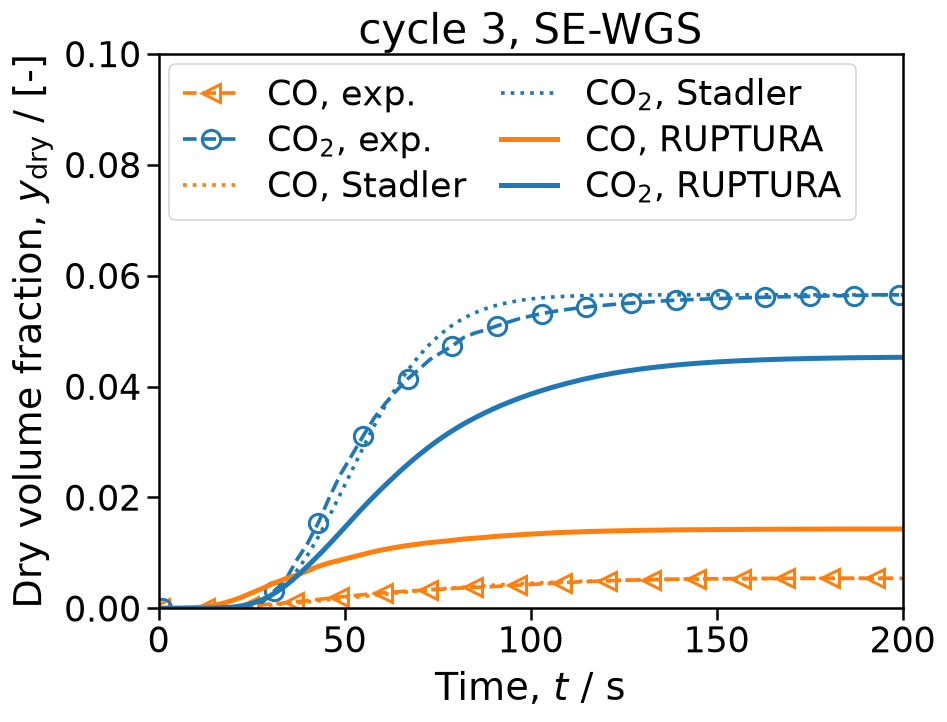

steady CO conversion: RUPTURA 0.760, measured 0.912 (Figure 8B plateaus; 0.896 in Section 3.3); plug flow with the Table 3 kinetics: 0.761 at 2000 mL/min, 0.844 at 1500 mL/min, 0.931 at 1000 mL/min


In [9]:
tracer = read_reference("figure8a_experiment_CO")
co_time, co_fraction = read_reference("figure8b_experiment_CO")
co2_time, co2_fraction = read_reference("figure8b_experiment_CO2")
model_co_time, model_co = read_reference("figure8b_simulation_CO")
model_co2_time, model_co2 = read_reference("figure8b_simulation_CO2")
time_s, co_simulated, co2_simulated = adsorption_step(SEWGS_CASE, 3, tracer)

fig, ax = plt.subplots()
plot_reference(ax, co_time, co_fraction, "C1", "<", label="CO, exp.")
plot_reference(ax, co2_time, co2_fraction, "C0", "o", label=r"CO$_2$, exp.")
ax.plot(model_co_time, model_co, color="C1", linestyle=":", linewidth=2.2, label="CO, Stadler")
ax.plot(model_co2_time, model_co2, color="C0", linestyle=":", linewidth=2.2, label=r"CO$_2$, Stadler")
ax.plot(time_s, co_simulated, color="C1", label="CO, RUPTURA")
ax.plot(time_s, co2_simulated, color="C0", label=r"CO$_2$, RUPTURA")
ax.set(xlim=(0.0, 200.0), ylim=(0.0, 0.1), title="cycle 3, SE-WGS",
       xlabel=r"Time, $t$ / s", ylabel=r"Dry volume fraction, $y_{\mathrm{dry}}$ / [-]")
ax.legend(loc="upper left", ncol=2)
fig.savefig(FIGURES / "figure_8b.pdf", bbox_inches="tight")
plt.show()

# Carbon-based conversion CO2/(CO + CO2) at the end of the step (the dry total also gains the H2 produced).
_, carbon_monoxide, carbon_dioxide = adsorption_step(SEWGS_CASE, 3)
measured_co, measured_co2 = co_fraction[co_time > 180.0].mean(), co2_fraction[co2_time > 180.0].mean()
print(f"steady CO conversion: RUPTURA {carbon_dioxide[-1] / (carbon_monoxide[-1] + carbon_dioxide[-1]):.3f}, "
      f"measured {measured_co2 / (measured_co + measured_co2):.3f} (Figure 8B plateaus; 0.896 in Section 3.3); "
      f"plug flow with the Table 3 kinetics: "
      + ", ".join(f"{plug_flow_conversion(523.15, 4.0, flow, 0.51e-3, 0.05):.3f} at {flow:.0f} mL/min"
                  for flow in (2000.0, 1500.0, 1000.0)))

## Breakthrough delay of CO$_2$ behind CO

$\Delta t_{50} = t_{50,\mathrm{CO_2}} - t_{50,\mathrm{CO}}$ between the half-heights of the
normalised curves, at the analyser.  For RUPTURA the curves are passed through the
same measured response as in the figures above.  In SE-WGS, CO reacts, so the CO of
Figure 8A (same set-up and flow; the model's own Figure 8A CO for the authors' model)
is the reference.

In [10]:
rows = {}
for cycle in range(1, NUMBER_OF_CYCLES + 1):
    rows[f"sorbent only, experiment, cycle {cycle}"] = half_times(
        *read_reference(f"figure6_cycle{cycle}_CO"), *read_reference(f"figure6_cycle{cycle}_CO2"))
    time_s, co, co2 = adsorption_step(SORBENT_ONLY_CASE, cycle, read_reference(f"figure6_cycle{cycle}_CO"))
    rows[f"sorbent only, RUPTURA, cycle {cycle}"] = half_times(time_s, co, time_s, co2)
rows["sorbent only, Stadler et al., cycle 3"] = half_times(
    *read_reference("figure8a_simulation_CO"), *read_reference("figure8a_simulation_CO2"))
# In SE-WGS, CO reacts and is no tracer: the CO of Figure 8A (same set-up and flow) is the reference.
rows["SE-WGS, experiment, cycle 3"] = half_times(
    *read_reference("figure8a_experiment_CO"), *read_reference("figure8b_experiment_CO2"))
rows["SE-WGS, Stadler et al., cycle 3"] = half_times(
    *read_reference("figure8a_simulation_CO"), *read_reference("figure8b_simulation_CO2"))
time_s, _, co2 = adsorption_step(SEWGS_CASE, 3, read_reference("figure8a_experiment_CO"))
rows["SE-WGS, RUPTURA, cycle 3"] = half_times(*read_reference("figure8a_experiment_CO"), time_s, co2)

delay = pd.DataFrame(rows, index=["t50 CO / s", "t50 CO2 / s"]).T
delay["delay / s"] = delay["t50 CO2 / s"] - delay["t50 CO / s"]
delay.round(1)

,t50 CO / s,t50 CO2 / s,delay / s
"sorbent only, experiment, cycle 1",44.5,106.7,62.1
"sorbent only, RUPTURA, cycle 1",43.4,63.6,20.2
"sorbent only, experiment, cycle 2",44.1,62.9,18.8
"sorbent only, RUPTURA, cycle 2",43.5,61.2,17.7
"sorbent only, experiment, cycle 3",42.5,58.2,15.8
"sorbent only, RUPTURA, cycle 3",41.7,59.7,18.0
"sorbent only, experiment, cycle 4",43.3,55.6,12.4
"sorbent only, RUPTURA, cycle 4",42.4,60.1,17.7
"sorbent only, experiment, cycle 5",42.2,54.5,12.3
"sorbent only, RUPTURA, cycle 5",41.6,58.8,17.2


## Cyclic steady state

Bed-average CO$_2$ loading over the five simulated cycles.  Both runs are periodic from
the second cycle on; the first adsorption step starts from a clean bed.

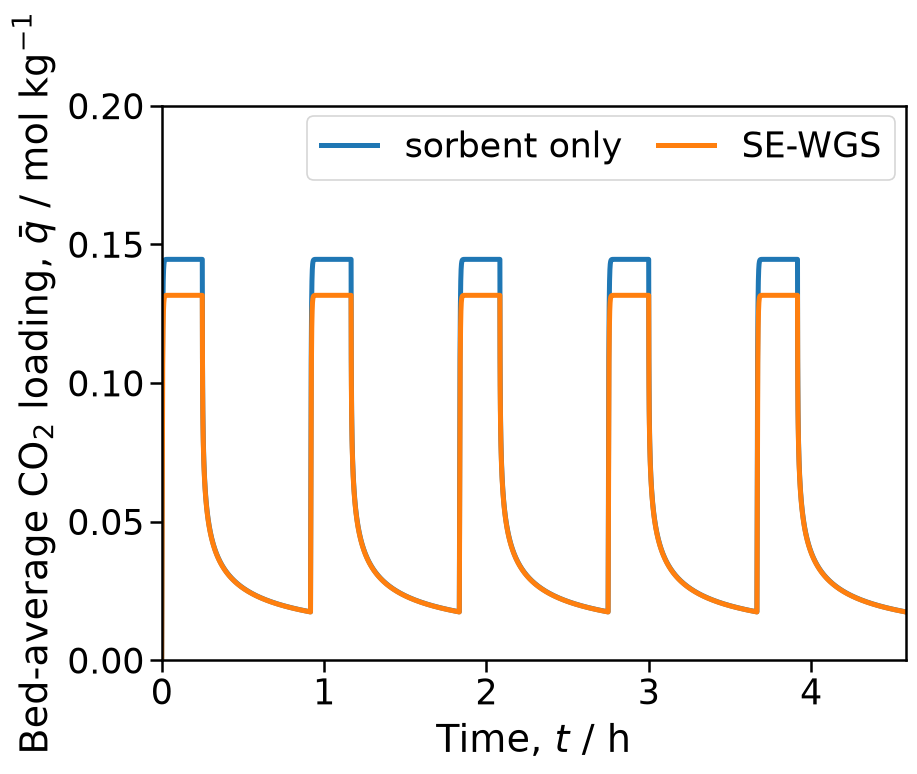

q end of adsorption / mol kg-1  \
sorbent only 1                          0.1446   
             2                          0.1446   
             3                          0.1446   
             4                          0.1446   
             5                          0.1446   
SE-WGS       1                          0.1317   
             2                          0.1317   
             3                          0.1317   
             4                          0.1317   
             5                          0.1317   

                q end of regeneration / mol kg-1  working capacity / mol kg-1  
sorbent only 1                            0.0175                       0.1272  
             2                            0.0175                       0.1272  
             3                            0.0175                       0.1272  
             4                            0.0175                       0.1272  
             5                            0.0175                       0.1272  
SE-WGS       1                            0.0174                       0.1142  
             2                            0.0174                       0.1142  
             3                            0.0174                       0.1142  
             4                            0.0174                       0.1142  
             5                            0.0174                       0.1142

In [11]:
fig, ax = plt.subplots()
for colour, case, label in (("C0", SORBENT_ONLY_CASE, "sorbent only"), ("C1", SEWGS_CASE, "SE-WGS")):
    time_s, loading = bed_average_loading(case)
    ax.plot(time_s / 3600.0, loading, color=colour, label=label)
ax.set(xlim=(0.0, NUMBER_OF_CYCLES * CYCLE_PERIOD / 3600.0), ylim=(0.0, 0.2),
       xlabel=r"Time, $t$ / h", ylabel=r"Bed-average CO$_2$ loading, $\bar q$ / mol kg$^{-1}$")
ax.legend(loc="upper right", ncol=2)
fig.savefig(FIGURES / "cyclic_loading.pdf", bbox_inches="tight")
plt.show()

summary = {}
for case, label in ((SORBENT_ONLY_CASE, "sorbent only"), (SEWGS_CASE, "SE-WGS")):
    time_s, loading = bed_average_loading(case)
    for cycle in range(1, NUMBER_OF_CYCLES + 1):
        start = (cycle - 1) * CYCLE_PERIOD
        # Last output at or before each switch; the first step at 1 bar already desorbs noticeably.
        end_adsorption = loading[time_s <= start + ADSORPTION_TIME + 1.0e-6][-1]
        end_regeneration = loading[time_s <= start + CYCLE_PERIOD + 1.0e-6][-1]
        summary[(label, cycle)] = (end_adsorption, end_regeneration, end_adsorption - end_regeneration)
pd.DataFrame(summary, index=["q end of adsorption / mol kg-1", "q end of regeneration / mol kg-1",
                             "working capacity / mol kg-1"]).T.round(4)

## Notes

* **Isotherm and kinetics.** RUPTURA reproduces the Table 3 Freundlich isotherm to machine
  precision. The Figure 4 conversions lie on the authors' model lines: over all 51 runs they are
  within 0.0007-0.0035 of an ideal plug-flow reactor. The remaining difference is axial dispersion,
  Eq. 12 plus the numerical part.
* **Numerical dispersion.** With the default WENO3 convection and the physical dispersion switched off,
  the conversion error falls with the square of the grid spacing, from 1.8e-4 with 25 cells to 3.8e-8
  with 1600 (first-order upwinding halved it with every doubling). For the breakthrough curves it does
  not matter, because their width is set by $k_{\mathrm{ads}}$ and by the tubing.
* **Sorbent-only cycles.**
  * Both simulations are periodic from the second cycle on.
  * The third-cycle delay of CO$_2$ behind CO is 18.0 s, against 17.9 s for the authors' model and
    15.8 s measured.
  * Cycle 1 cannot be matched by a model fitted from cycle 2 on. The measured 62 s include the
    irreversible carbonate formation.
  * The measured delay keeps shrinking over cycles 2-5 (18.8 to 12.3 s), which the model does not
    capture. The simulated delay is 17.2-18.0 s in cycles 2-5.
* **SE-WGS cycles.**
  * The WGS acts only in the catalyst quarter; downstream, H$_2$ is constant. Both runs are periodic
    from the second cycle on.
  * With the stated parameters at 2000 mL min$^{-1}$, RUPTURA converts 0.759 of the CO. That is what
    the Table 3 kinetics give in a plug-flow reactor (0.761).
  * The measurement converts 0.91 (Figure 8B plateaus; 0.896 in Section 3.3), and so does the authors' model.
  * The measured CO$_2$ front is also earlier: 10.6 s after the Figure 8A CO response, against 19.7 s for
    RUPTURA and 10.7 s for the authors' model. It is even earlier than in the sorbent-only cycle 3
    (16.3 s), although less CO$_2$ is produced.
  * The measured unconverted CO rises *after* the CO$_2$, and slowly: t$_{50}$ = 59 s and
    t$_{90}$ = 118 s, against 42 s and 90 s for the inert CO of Figure 8A. So the conversion is not
    constant during the step. It is higher at first, while the fresh sorbent takes up CO$_2$, and
    falls as the sorbent saturates.
  * Eq. 4 cannot produce this. Far from equilibrium ($X_{\mathrm{eq}}$ = 0.996 at $S/G$ = 4),
    removing CO$_2$ does not change the rate, so RUPTURA's CO follows the tracer. That would need a
    rate law in which CO$_2$ inhibits the reaction, as is typical of Cu/ZnO/Al$_2$O$_3$. The authors'
    model nevertheless shows the slow CO rise, so their Figure 8B simulation is not Eq. 4 with
    Table 3 as printed.
  * The measured CO$_2$ front moves earlier every cycle: t$_{50}$ = 66.7, 52.4, 45.3, 37.9 and 36.5 s
    in cycles 1, 3, 13, 43 and 63 (36.6 s from the digitized curve). The SE-WGS sorbent loses capacity quickly, faster than the
    sorbent-only bed.
  * Scratch sensitivity runs (three cycles, 10 cells over the catalyst quarter; upwind binary of 2026-10-21, not kept):
    * 1400 mL min$^{-1}$: $X$ = 0.83, but the CO$_2$ front moves *later*, to 68.6 s.
    * A 1.7$\times$ more active catalyst: $X$ = 0.87, front at 59.9 s.
    * The same catalyst with 40 % less sorbent capacity: front at 52.9 s, against 52.5 s measured.
  * Figure 8B therefore needs a faster reaction and a smaller cyclic capacity than the published
    parameters give. It is not a clean validation target with those parameters. Confirm the conditions
    of the 2022 SE-WGS runs with the authors.
* **Plateaus.** The measured and authors' plateaus in Figures 6 and 8A are about 0.066 dry, against
  0.05/(1 - 0.2) = 0.0625 for the stated feed. RUPTURA's plateau is exactly 0.0625.